In [8]:
#import sys
#!{sys.executable} -m pip install scikit-rf
import skrf as rf

ntwk = rf.Network("../data/Tx_1x24_RP_HFSSDesign1.s24p")

print(ntwk)

24-Port Network: 'Tx_1x24_RP_HFSSDesign1',  3.4-3.6 GHz, 3 pts, z0=[50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j
 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j
 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j 50.+0.j]


Introduction to networks : from [scikit-rf documentation on readthedocs](https://scikit-rf.readthedocs.io/en/latest/tutorials/Networks.html?utm_source=chatgpt.com)

N-port microwave network : https://scikit-rf.readthedocs.io/en/latest/api/network.html

N-port networks are characterised by Z, Y, ABCD, h parameters just like regular two port networks that were covered in ECSE 210. However instead of using V,I they use travelling wave variables (ex. a,b).

$a_i$ corresponds to the wave amplitude travelling INTO the network at port i.

$b_i$ corresponds to the wave amplitude travelling OUT OF the network at port i.

S parameters are therefore used like so :

$$
\begin{bmatrix}
b_1\\
b_2
\end{bmatrix}
=
\begin{bmatrix}
S_{11} & S_{12}\\
S_{21} & S_{22}
\end{bmatrix}
\begin{bmatrix}
a_1\\
a_2
\end{bmatrix}
$$






In [9]:
print(ntwk.s)

[[[-1.85668243e-02+8.46019797e-03j  1.14676984e-01-7.92592239e-02j
   -7.59862401e-02+4.47781051e-02j ... -7.02155982e-03-3.39961856e-04j
    7.46269195e-03-1.18407103e-03j -8.64300801e-03+1.83037532e-03j]
  [ 1.14676984e-01-7.92592239e-02j  8.22557248e-02+4.69023283e-02j
    6.63511301e-02-8.87930946e-02j ...  4.90909568e-03-1.72334723e-04j
   -5.72971633e-03+1.07863701e-03j  6.50310042e-03-7.41222601e-04j]
  [-7.59862401e-02+4.47781051e-02j  6.63511301e-02-8.87930946e-02j
    1.04224426e-01+4.69606768e-02j ... -3.18288637e-03-7.74595677e-04j
    4.34377606e-03+9.08558417e-05j -5.42187562e-03-9.98163567e-04j]
  ...
  [-7.02155982e-03-3.39961857e-04j  4.90909567e-03-1.72334716e-04j
   -3.18288637e-03-7.74595677e-04j ...  9.16387877e-02+3.10111511e-02j
    7.73644334e-02-7.07498760e-02j -8.48058624e-02+2.24599604e-02j]
  [ 7.46269195e-03-1.18407105e-03j -5.72971633e-03+1.07863701e-03j
    4.34377607e-03+9.08558352e-05j ...  7.73644334e-02-7.07498760e-02j
    7.19930946e-02+2.33368574e-0

S matrix shape: (3, 24, 24)
Frequencies (GHz): [3.4 3.5 3.6]
Chosen frequency: 3.5 GHz
Hsi shape: (12, 12)


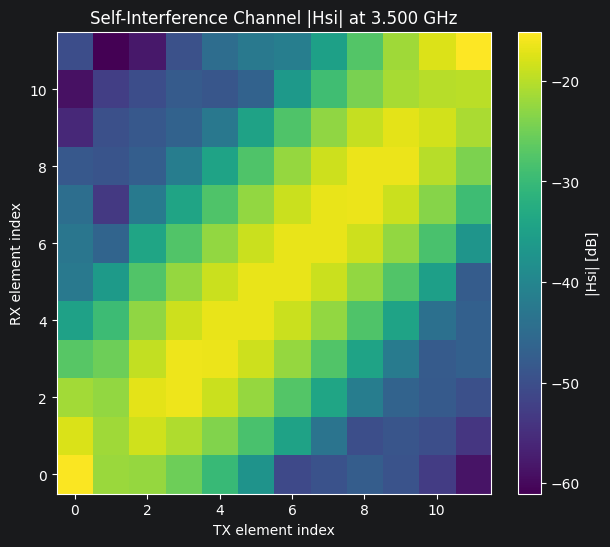

In [15]:
import skrf as rf
import numpy as np
import matplotlib.pyplot as plt

# Load Touchstone file
ntwk = rf.Network("../data/Tx_1x24_RP_HFSSDesign1.s24p")

# Check dimensions
print("S matrix shape:", ntwk.s.shape)   # should be (Nfreq, 24, 24)
print("Frequencies (GHz):", ntwk.f / 1e9)
target_freq = 3.5e9
idx = np.argmin(np.abs(ntwk.f - target_freq))

print("Chosen frequency:", ntwk.f[idx] / 1e9, "GHz")

S = ntwk.s[idx]   # shape (24, 24)
tx_idx = np.arange(0, 24, 2)   # 0,2,4,...,22
rx_idx = np.arange(1, 24, 2)   # 1,3,5,...,23

Hsi = S[np.ix_(rx_idx, tx_idx)]   # shape (12, 12)

print("Hsi shape:", Hsi.shape)
Hsi_db = 20 * np.log10(np.maximum(np.abs(Hsi), 1e-15))

plt.figure(figsize=(7, 6))
plt.imshow(Hsi_db, origin="lower", aspect="auto")
plt.colorbar(label="|Hsi| [dB]")
plt.xlabel("TX element index")
plt.ylabel("RX element index")
plt.title(f"Self-Interference Channel |Hsi| at {ntwk.f[idx]/1e9:.3f} GHz")
plt.show()